<a href="https://colab.research.google.com/github/nergisulusu/Economics-Workshop/blob/main/replication_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Income and Democracy: Replication Assignment

Replication of Acemoglu et al. (2008).

- Main result: Table 2, Column 2 (two-way fixed effects).
- Extension: Table 4, Column 3 (excluding countries coded as Soviet Bloc in the dataset).
- Supplementary descriptive analysis: 1970–1995 changes in income and democracy.

**To run in Google Colab:** run the cells from top to bottom. When prompted, upload `Income-and-Democracy-Data-AER-adjustment.xls`.

In [ ]:
%pip install linearmodels xlrd pandas numpy matplotlib seaborn scipy openpyxl

In [31]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from linearmodels.panel import PanelOLS
from scipy.stats import linregress


# Required packages: pandas, numpy, matplotlib, seaborn,
# linearmodels, scipy, and xlrd.
# Install before running:
# python -m pip install pandas numpy matplotlib seaborn linearmodels scipy xlrd

In [32]:

# Load the five-year panel dataset.
from google.colab import files
from pathlib import Path

dataset_name = "Income-and-Democracy-Data-AER-adjustment.xls"
file_path = Path("/content") / dataset_name

if not file_path.exists():
    print("Please upload the Excel dataset.")
    uploaded = files.upload()

    if dataset_name not in uploaded:
        raise FileNotFoundError(
            f"Please upload the file named {dataset_name}."
        )

    file_path = Path("/content") / dataset_name

df_5yr = pd.read_excel(
    file_path,
    sheet_name="5 Year Panel"
)

# Check required variables.
required = [
    "country", "year", "fhpolrigaug",
    "lrgdpch", "sample", "socialist"
]

missing = [
    col for col in required
    if col not in df_5yr.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

print("Dataset loaded successfully.")
print("Observations:", len(df_5yr))


Dataset loaded successfully.
Observations: 2321


In [33]:
# Sort the data and check country-year observations.
df_5yr = df_5yr.sort_values(
    ["country", "year"]
).reset_index(drop=True)

if df_5yr.duplicated(["country", "year"]).any():
    raise ValueError("Duplicate country-year observations found.")

print("Observations:", len(df_5yr))
print("Countries:", df_5yr["country"].nunique())
print("Year range:", df_5yr["year"].min(), "-", df_5yr["year"].max())

print("\nMissing values:")
print(df_5yr[required].isna().sum())

Observations: 2321
Countries: 211
Year range: 1950 - 2000

Missing values:
country           0
year              0
fhpolrigaug     804
lrgdpch        1090
sample            0
socialist         0
dtype: int64


In [ ]:
# Create five-year lagged variables.
df_5yr["year_lag1"] = (
    df_5yr.groupby("country")["year"].shift(1)
)

valid_lag = (
    df_5yr["year"] - df_5yr["year_lag1"] == 5
)

for variable in ["lrgdpch", "fhpolrigaug"]:
    df_5yr[f"{variable}_lag1"] = (
        df_5yr.groupby("country")[variable]
        .shift(1)
        .where(valid_lag)
    )

# Check the lag intervals.
print("Lag interval counts:")
print(
    (df_5yr["year"] - df_5yr["year_lag1"])
    .value_counts(dropna=False)
    .sort_index()
)

Lag interval counts:
5.0    2110
NaN     211
Name: count, dtype: int64


In [ ]:
# Prepare the main regression sample.
fe_df = (
    df_5yr[df_5yr["sample"] == 1]
    .dropna(
        subset=[
            "fhpolrigaug",
            "fhpolrigaug_lag1",
            "lrgdpch_lag1"
        ]
    )
    .copy()
)

print("Main regression sample:")
print("Observations:", len(fe_df))
print("Countries:", fe_df["country"].nunique())
print("Years:", fe_df["year"].nunique())
print("Year range:", fe_df["year"].min(), "-", fe_df["year"].max())

Main regression sample:
Observations: 945
Countries: 150
Years: 9
Year range: 1960 - 2000


In [ ]:
# Main replication: Table 2, Column 2.
fe_model = PanelOLS.from_formula(
    "fhpolrigaug ~ 1 + fhpolrigaug_lag1 + lrgdpch_lag1 "
    "+ EntityEffects + TimeEffects",
    data=fe_df.set_index(["country", "year"])
)

fe_results = fe_model.fit(
    cov_type="clustered",
    cluster_entity=True
)

print("\nMAIN REPLICATION: TABLE 2, COLUMN 2")
print(fe_results.summary)


MAIN REPLICATION: TABLE 2, COLUMN 2
                          PanelOLS Estimation Summary                           
Dep. Variable:            fhpolrigaug   R-squared:                        0.1436
Estimator:                   PanelOLS   R-squared (Between):              0.5936
No. Observations:                 945   R-squared (Within):               0.1638
Date:                Tue, Nov 10 2026   R-squared (Overall):              0.4976
Time:                        21:27:21   Log-likelihood                    367.02
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      65.819
Entities:                         150   P-value                           0.0000
Avg Obs:                       6.3000   Distribution:                   F(2,785)
Min Obs:                       1.0000                                           
Max Obs:                       9.0000   F-statistic (robust):           

In [ ]:
# Calculate changes between 1970 and 1995 for all countries.
sub_df_all = df_5yr[
    df_5yr["year"].isin([1970, 1995])
].dropna(subset=["fhpolrigaug", "lrgdpch"])

pivoted_all = sub_df_all.pivot(
    index="country",
    columns="year",
    values=["fhpolrigaug", "lrgdpch"]
)

changes_all = pd.DataFrame({
    "d_fh": (
        pivoted_all[("fhpolrigaug", 1995)]
        - pivoted_all[("fhpolrigaug", 1970)]
    ),
    "d_income": (
        pivoted_all[("lrgdpch", 1995)]
        - pivoted_all[("lrgdpch", 1970)]
    )
}).dropna()

print("Countries in the full sample:", len(changes_all))

Countries in the full sample: 103


In [ ]:
# Calculate changes for non-socialist countries.
sub_df_non_socialist = df_5yr[
    (df_5yr["year"].isin([1970, 1995])) &
    (df_5yr["socialist"] == 0)
].dropna(subset=["fhpolrigaug", "lrgdpch"])

pivoted_non_socialist = sub_df_non_socialist.pivot(
    index="country",
    columns="year",
    values=["fhpolrigaug", "lrgdpch"]
)

changes_non_socialist = pd.DataFrame({
    "d_fh": (
        pivoted_non_socialist[("fhpolrigaug", 1995)]
        - pivoted_non_socialist[("fhpolrigaug", 1970)]
    ),
    "d_income": (
        pivoted_non_socialist[("lrgdpch", 1995)]
        - pivoted_non_socialist[("lrgdpch", 1970)]
    )
}).dropna()

print(
    "Countries in the non-socialist sample:",
    len(changes_non_socialist)
)

Countries in the non-socialist sample: 101


In [ ]:
# Calculate correlations and regression slopes.
slope_all, intercept_all = np.polyfit(
    changes_all["d_income"],
    changes_all["d_fh"],
    1
)

slope_non_socialist, intercept_non_socialist = np.polyfit(
    changes_non_socialist["d_income"],
    changes_non_socialist["d_fh"],
    1
)

corr_all = changes_all["d_income"].corr(changes_all["d_fh"])
corr_non_socialist = changes_non_socialist["d_income"].corr(
    changes_non_socialist["d_fh"]
)

print("Full sample correlation:", corr_all)
print("Full sample slope:", slope_all)
print("Non-socialist sample correlation:", corr_non_socialist)
print("Non-socialist sample slope:", slope_non_socialist)

Full sample correlation: 0.05157816271787648
Full sample slope: 0.032980804053131106
Non-socialist sample correlation: 0.03775745804581076
Non-socialist sample slope: 0.02360440765208669


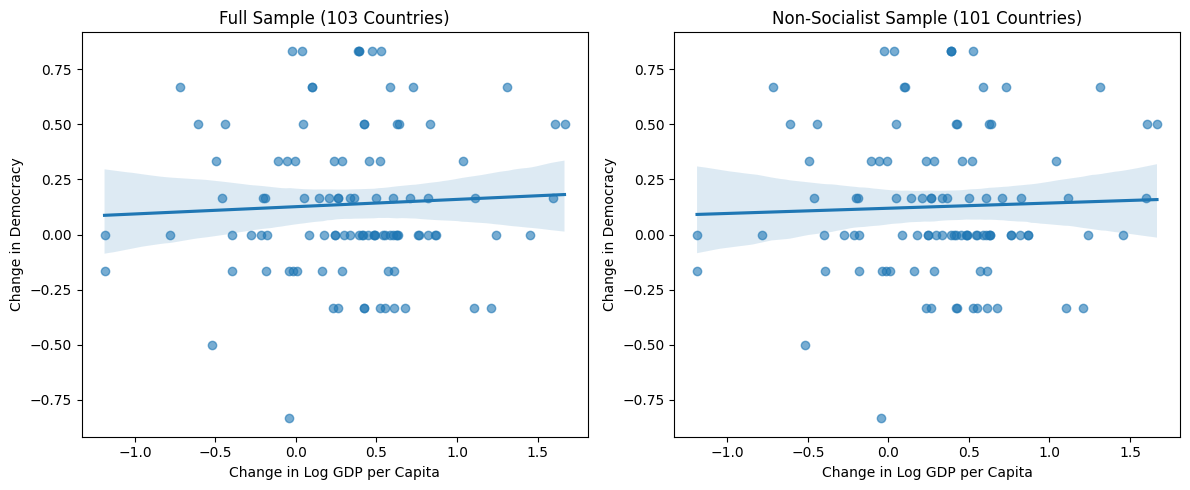

In [ ]:
# Visualize the relationship between income and democracy changes.
plt.figure(figsize=(12, 5))

# Full sample.
plt.subplot(1, 2, 1)
sns.regplot(
    data=changes_all,
    x="d_income",
    y="d_fh",
    scatter_kws={"alpha": 0.6}
)
plt.title(f"Full Sample ({len(changes_all)} Countries)")
plt.xlabel("Change in Log GDP per Capita")
plt.ylabel("Change in Democracy")

# Non-socialist sample.
plt.subplot(1, 2, 2)
sns.regplot(
    data=changes_non_socialist,
    x="d_income",
    y="d_fh",
    scatter_kws={"alpha": 0.6}
)
plt.title(
    f"Non-Socialist Sample ({len(changes_non_socialist)} Countries)"
)
plt.xlabel("Change in Log GDP per Capita")
plt.ylabel("Change in Democracy")

plt.tight_layout()
plt.show()

In [ ]:
# Estimate linear regressions for both descriptive samples.
result_all = linregress(
    changes_all["d_income"],
    changes_all["d_fh"]
)

result_non_socialist = linregress(
    changes_non_socialist["d_income"],
    changes_non_socialist["d_fh"]
)

print("\nFULL SAMPLE")
print("Slope:", result_all.slope)
print("P-value:", result_all.pvalue)
print("Standard error:", result_all.stderr)
print("Number of observations:", len(changes_all))

print("\nNON-SOCIALIST SAMPLE")
print("Slope:", result_non_socialist.slope)
print("P-value:", result_non_socialist.pvalue)
print("Standard error:", result_non_socialist.stderr)
print("Number of observations:", len(changes_non_socialist))


FULL SAMPLE
Slope: 0.032980804053131044
P-value: 0.6048648521258172
Standard error: 0.0635413205604376
Number of observations: 103

NON-SOCIALIST SAMPLE
Slope: 0.023604407652086632
P-value: 0.7077584459473467
Standard error: 0.06278602216520923
Number of observations: 101


In [ ]:
# Prepare the non-socialist sample for the FE extension.
# The dataset's socialist indicator identifies the Soviet Bloc,
# including countries behind the Iron Curtain.
non_socialist_fe_df = (
    df_5yr.loc[
        (df_5yr["sample"] == 1) &
        (df_5yr["socialist"] == 0)
    ]
    .dropna(
        subset=[
            "fhpolrigaug",
            "fhpolrigaug_lag1",
            "lrgdpch_lag1"
        ]
    )
    .copy()
)

print(
    "Non-socialist FE sample observations:",
    len(non_socialist_fe_df)
)
print(
    "Non-socialist FE sample countries:",
    non_socialist_fe_df["country"].nunique()
)
print(
    "Non-socialist FE sample years:",
    non_socialist_fe_df["year"].nunique()
)

Non-socialist FE sample observations: 908
Non-socialist FE sample countries: 128
Non-socialist FE sample years: 9


In [29]:
print("\nSocialist indicator in main sample:")
print(fe_df["socialist"].value_counts(dropna=False).sort_index())

print("\nSocialist indicator in non-socialist sample:")
print(non_socialist_fe_df["socialist"].value_counts(dropna=False).sort_index())


Socialist indicator in main sample:
socialist
0    908
1     37
Name: count, dtype: int64

Socialist indicator in non-socialist sample:
socialist
0    908
Name: count, dtype: int64


In [30]:

# Check the panel structure of the main sample.
print("Unique countries:", fe_df["country"].nunique())
print("Unique years:", sorted(fe_df["year"].unique()))
print("Observations:", len(fe_df))

# Check for duplicate country-year observations.
print(
    "Duplicate country-year observations:",
    fe_df.duplicated(["country", "year"]).sum()
)


Unique countries: 150
Unique years: [np.int64(1960), np.int64(1965), np.int64(1970), np.int64(1975), np.int64(1980), np.int64(1985), np.int64(1990), np.int64(1995), np.int64(2000)]
Observations: 945
Duplicate country-year observations: 0


In [ ]:
# Extension: Table 4, Column 3.
non_socialist_model = PanelOLS.from_formula(
    "fhpolrigaug ~ 1 + fhpolrigaug_lag1 + "
    "lrgdpch_lag1 + EntityEffects + TimeEffects",
    data=non_socialist_fe_df.set_index(["country", "year"])
)

non_socialist_results = non_socialist_model.fit(
    cov_type="clustered",
    cluster_entity=True
)

print("\nEXTENSION: TABLE 4, COLUMN 3")
print(non_socialist_results.summary)


EXTENSION: TABLE 4, COLUMN 3
                          PanelOLS Estimation Summary                           
Dep. Variable:            fhpolrigaug   R-squared:                        0.1318
Estimator:                   PanelOLS   R-squared (Between):              0.5841
No. Observations:                 908   R-squared (Within):               0.1456
Date:                Tue, Nov 10 2026   R-squared (Overall):              0.4710
Time:                        21:27:45   Log-likelihood                    349.60
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      58.465
Entities:                         128   P-value                           0.0000
Avg Obs:                       7.0938   Distribution:                   F(2,770)
Min Obs:                       1.0000                                           
Max Obs:                       9.0000   F-statistic (robust):             24.78